# Khám phá dữ liệu PEMS08

- `data.pkl`: dữ liệu đưa vào model — Flow chuẩn hóa, mã giờ, mã ngày.
- `min.pkl`, `max.pkl`: scaler để đưa Flow về đơn vị gốc.
- `raw/pems08.npz`: bản ba kênh Flow, Occupancy, Speed đã có trên máy.
- `train_index.pkl`, `valid_index.pkl`, `test_index.pkl`: các cửa sổ forecast thực tế.

Bảng và hình tự lưu vào `results/eda/PEMS08/`. Notebook chạy CPU, không cần Torch.


## 1. Import thư viện


In [71]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 2. Chọn thư mục dữ liệu


In [72]:
ROOT = Path.cwd()
if not (ROOT / 'datasets').exists():
    ROOT = ROOT.parent

DATA = ROOT / 'datasets' / 'PEMS08'
OUTPUT = ROOT / 'results' / 'eda' / 'PEMS08'
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Dữ liệu:', DATA)


Dữ liệu: d:\Project_Github\predictiveDA\datasets\PEMS08


## 3. Đọc dữ liệu đã xử lý


In [73]:
with open(DATA / 'data.pkl', 'rb') as file:
    data = pickle.load(file, encoding='latin1')

print('Kích thước:', data.shape)
print('Thứ tự: số thời điểm, số node, số kênh')
print('Các kênh: Flow chuẩn hóa, mã giờ, mã ngày')


Kích thước: (17856, 170, 3)
Thứ tự: số thời điểm, số node, số kênh
Các kênh: Flow chuẩn hóa, mã giờ, mã ngày


## 4. Đọc scaler và khôi phục Flow


In [74]:
with open(DATA / 'min.pkl', 'rb') as file:
    flow_min = float(pickle.load(file, encoding='latin1')[0, 0, 0])
with open(DATA / 'max.pkl', 'rb') as file:
    flow_max = float(pickle.load(file, encoding='latin1')[0, 0, 0])

flow_from_model = (data[:, :, 0] + 1) / 2 * (flow_max - flow_min) + flow_min
print('Min/max scaler:', flow_min, flow_max)


Min/max scaler: 0.0 1077.0


## 5. Đọc Flow, Occupancy và Speed trong file có sẵn


In [75]:
with np.load(DATA / 'raw' / 'pems08.npz', allow_pickle=False) as file:
    raw = file['data']

flow = raw[:, :, 0]
occupancy = raw[:, :, 1]
speed = raw[:, :, 2]
print('Kích thước bản gốc:', raw.shape)


Kích thước bản gốc: (17856, 170, 3)


## 6. Kiểm tra Flow khớp với dữ liệu thực nghiệm


In [76]:
assert raw.shape == data.shape == (17856, 170, 3)
assert np.allclose(flow, flow_from_model, atol=1e-8, rtol=0, equal_nan=True)
print('Sai khác Flow lớn nhất:', np.nanmax(np.abs(flow - flow_from_model)))


Sai khác Flow lớn nhất: 1.1368683772161603e-13


## 7. Đếm NaN

Đếm trên toàn bộ node và thời điểm. Không có NaN trong bản benchmark đã xử lý không có nghĩa dữ liệu cảm biến ban đầu chưa từng thiếu.


In [77]:
nan_counts = pd.DataFrame({
    'Đại lượng': ['Flow', 'Occupancy', 'Speed'],
    'Số NaN': [np.isnan(flow).sum(), np.isnan(occupancy).sum(), np.isnan(speed).sum()]
})
display(nan_counts)
nan_counts.to_csv(OUTPUT / 'nan_counts.csv', index=False, encoding='utf-8-sig')


,Đại lượng,Số NaN
0,Flow,0
1,Occupancy,0
2,Speed,0


## 8. Đếm giá trị 0

Giữ nguyên giá trị 0; không tự thay bằng NaN. Thiếu cờ chất lượng gốc nên chưa thể kết luận số 0 do không có xe hay do cảm biến. Occupancy trong file là tỷ phần 0–1.


In [78]:
zero_counts = pd.DataFrame({
    'Đại lượng': ['Flow', 'Occupancy', 'Speed'],
    'Số giá trị 0': [(flow == 0).sum(), (occupancy == 0).sum(), (speed == 0).sum()],
    'Tỷ lệ 0 (%)': [(flow == 0).mean() * 100,
                   (occupancy == 0).mean() * 100,
                   (speed == 0).mean() * 100]
})
display(zero_counts)
zero_counts.to_csv(OUTPUT / 'zero_counts.csv', index=False, encoding='utf-8-sig')


,Đại lượng,Số giá trị 0,Tỷ lệ 0 (%)
0,Flow,10560,0.347881
1,Occupancy,10560,0.347881
2,Speed,0,0.000000


## 9. Thống kê mô tả Flow
Đơn vị: xe/5 phút/node. Giữ số 0 trong thống kê.


In [79]:
flow_stats = pd.Series(flow.ravel(), name='Flow').describe()
display(flow_stats)
flow_stats.to_csv(OUTPUT / 'flow_descriptive.csv', encoding='utf-8-sig')


count    3.035520e+06
mean     2.306807e+02
std      1.462170e+02
min      0.000000e+00
25%      1.100000e+02
50%      2.150000e+02
75%      3.340000e+02
max      1.147000e+03
Name: Flow, dtype: float64

## 10. Thống kê mô tả Occupancy
Đơn vị: tỷ phần 0–1.


In [80]:
occupancy_stats = pd.Series(occupancy.ravel(), name='Occupancy').describe()
display(occupancy_stats)
occupancy_stats.to_csv(OUTPUT / 'occupancy_descriptive.csv', encoding='utf-8-sig')


count    3.035520e+06
mean     6.507109e-02
std      4.590215e-02
min      0.000000e+00
25%      3.570000e-02
50%      6.010000e-02
75%      8.390000e-02
max      8.955000e-01
Name: Occupancy, dtype: float64

## 11. Thống kê mô tả Speed

Giữ đơn vị gốc benchmark. File NPZ không nhúng metadata đơn vị nên không tự đổi sang km/h.


In [81]:
speed_stats = pd.Series(speed.ravel(), name='Speed').describe()
display(speed_stats)
speed_stats.to_csv(OUTPUT / 'speed_descriptive.csv', encoding='utf-8-sig')


count    3.035520e+06
mean     6.376300e+01
std      6.652010e+00
min      3.000000e+00
25%      6.260000e+01
50%      6.490000e+01
75%      6.740000e+01
max      8.230000e+01
Name: Speed, dtype: float64

## 12. Histogram Flow

**Hình 1.** Phân phối Flow ở tất cả node và thời điểm, giữ giá trị 0.


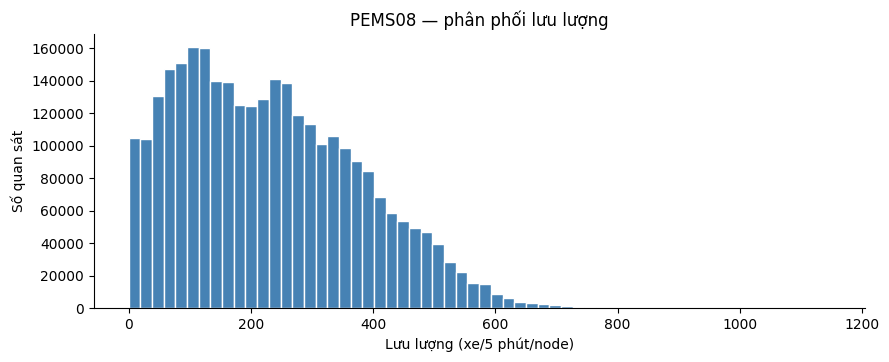

In [82]:
plt.figure(figsize=(9, 4))
plt.hist(flow.ravel(), bins=60, color='steelblue', edgecolor='white')
plt.title('PEMS08 — phân phối lưu lượng')
plt.xlabel('Lưu lượng (xe/5 phút/node)')
plt.ylabel('Số quan sát')
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(OUTPUT / '01_histogram_flow.png', dpi=180)
plt.show()
plt.close()


## 13. Histogram Occupancy

**Hình 2.** Mức chiếm dụng, nhân tỷ phần gốc với 100 để hiển thị %.


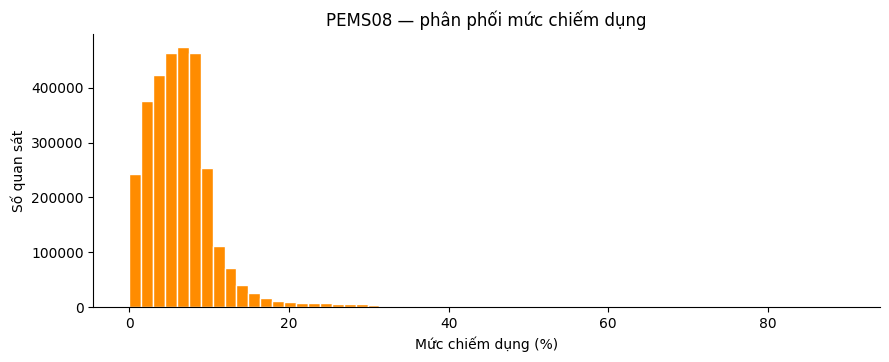

In [83]:
plt.figure(figsize=(9, 4))
plt.hist(occupancy.ravel() * 100, bins=60, color='darkorange', edgecolor='white')
plt.title('PEMS08 — phân phối mức chiếm dụng')
plt.xlabel('Mức chiếm dụng (%)')
plt.ylabel('Số quan sát')
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(OUTPUT / '02_histogram_occupancy.png', dpi=180)
plt.show()
plt.close()


## 14. Histogram Speed

**Hình 3.** Phân phối tốc độ, giữ đơn vị gốc benchmark.


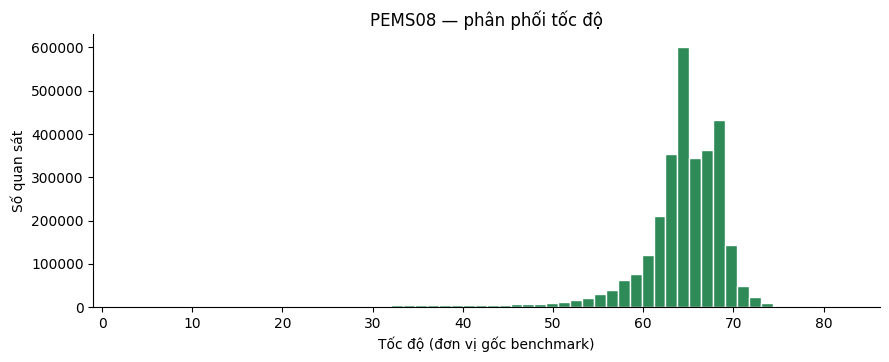

In [84]:
plt.figure(figsize=(9, 4))
plt.hist(speed.ravel(), bins=60, color='seagreen', edgecolor='white')
plt.title('PEMS08 — phân phối tốc độ')
plt.xlabel('Tốc độ (đơn vị gốc benchmark)')
plt.ylabel('Số quan sát')
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(OUTPUT / '03_histogram_speed.png', dpi=180)
plt.show()
plt.close()


## 15. Tạo trục thời gian


In [85]:
time = pd.date_range(start='2016-07-01', periods=len(flow), freq='5min')
print('Bắt đầu:', time[0])
print('Kết thúc:', time[-1])
print('Số ngày:', len(flow) / 288)


Bắt đầu: 2016-07-01 00:00:00
Kết thúc: 2016-08-31 23:55:00
Số ngày: 62.0


## 16. Chuỗi thời gian tại ba node

**Hình 4.** Flow trong bảy ngày đầu tại node 0, 85, 169 (chỉ số cột, không phải mã detector).


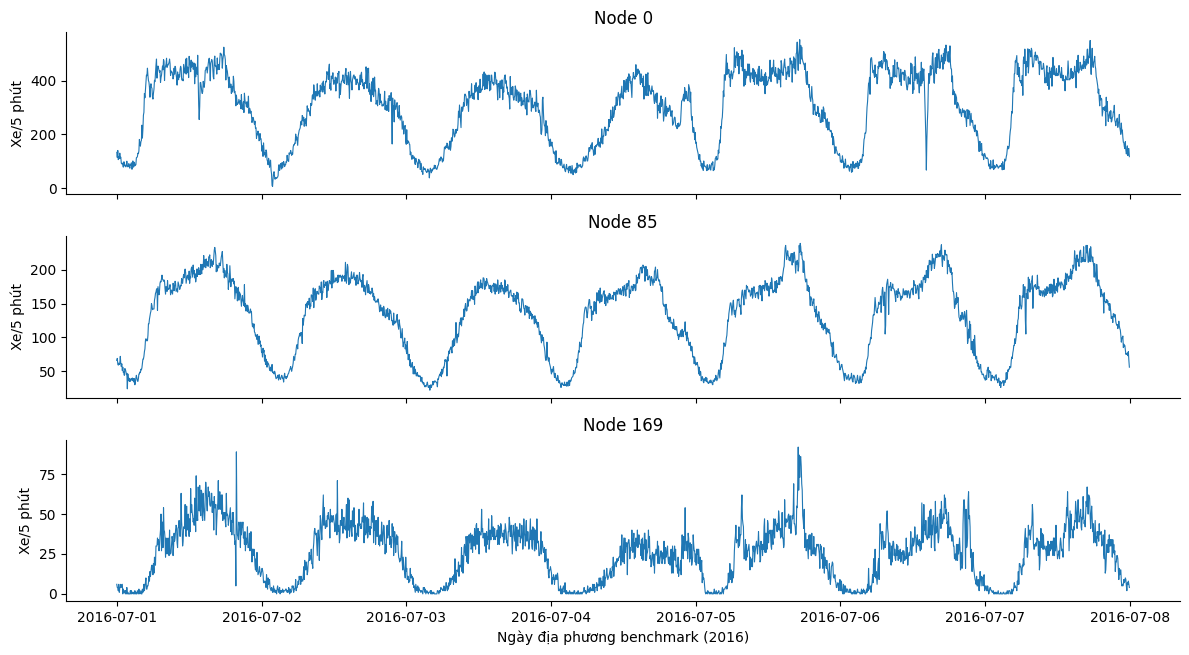

In [86]:
nodes = [0, 85, 169]
number_of_steps = 7 * 288  # 7 ngày, mỗi ngày 288 bước 5 phút

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, node in zip(axes, nodes):
    ax.plot(time[:number_of_steps], flow[:number_of_steps, node], linewidth=0.8)
    ax.set_title('Node ' + str(node))
    ax.set_ylabel('Xe/5 phút')
axes[-1].set_xlabel('Ngày địa phương benchmark (2016)')
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(OUTPUT / '04_node_timeseries.png', dpi=180)
plt.show()
plt.close()


## 17. Flow trung bình của các node tại mỗi thời điểm

Dữ liệu đã kiểm tra không có NaN. Lấy trung bình trên 170 node, giữ các số 0.


In [87]:
assert np.isfinite(flow).all(), 'Cần xử lý riêng NaN/Inf trước khi lấy trung bình.'
traffic = pd.DataFrame({'Flow': flow.mean(axis=1)}, index=time)
traffic['Giờ'] = traffic.index.hour
traffic['Thứ'] = traffic.index.dayofweek  # Theo lịch thật: 0 là thứ Hai
display(traffic.head())


,Flow,Giờ,Thứ
2016-07-01 00:00:00,111.682353,0,4
2016-07-01 00:05:00,110.423529,0,4
2016-07-01 00:10:00,109.829412,0,4
2016-07-01 00:15:00,107.347059,0,4
2016-07-01 00:20:00,103.335294,0,4


## 18. Tính trung bình theo giờ
Đơn vị vẫn là xe/5 phút/node, không phải tổng xe/giờ.


In [88]:
flow_by_hour = traffic.groupby('Giờ')['Flow'].mean()
display(flow_by_hour)
flow_by_hour.to_csv(OUTPUT / 'mean_flow_by_hour.csv', encoding='utf-8-sig')


Giờ
0     100.344023
1      78.163362
2      70.412018
3      80.448719
4     129.394118
5     190.631586
6     240.403289
7     275.030131
8     273.913955
9     273.305653
10    283.088876
11    294.615141
12    305.140291
13    312.358191
14    323.236330
15    328.936306
16    327.050221
17    324.503716
18    296.418058
19    260.846118
20    236.687540
21    215.229380
22    178.938749
23    137.240892
Name: Flow, dtype: float64

## 19. Vẽ Flow trung bình theo giờ

**Hình 5.** Trung bình toàn bộ node, ngày và thời điểm trong cùng giờ.


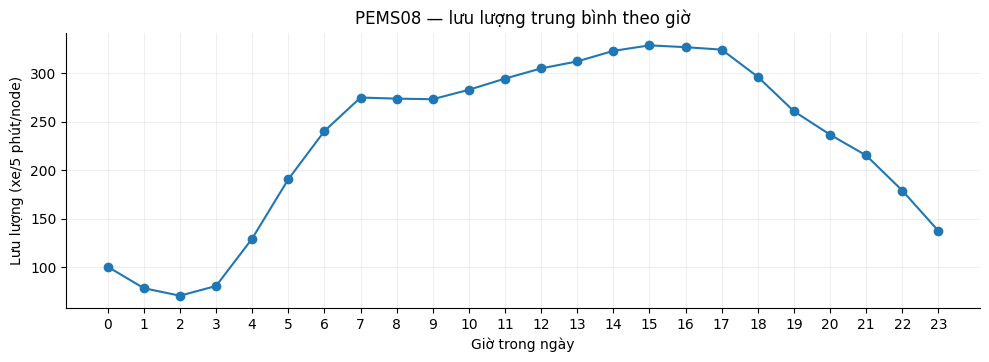

In [89]:
plt.figure(figsize=(10, 4))
plt.plot(flow_by_hour.index, flow_by_hour.values, marker='o')
plt.xticks(range(24))
plt.title('PEMS08 — lưu lượng trung bình theo giờ')
plt.xlabel('Giờ trong ngày')
plt.ylabel('Lưu lượng (xe/5 phút/node)')
plt.grid(alpha=0.2)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(OUTPUT / '05_mean_flow_by_hour.png', dpi=180)
plt.show()
plt.close()


## 20. Tính trung bình theo thứ
Đơn vị vẫn là xe/5 phút/node, không phải tổng xe/ngày.


In [90]:
day_names = ['Thứ Hai', 'Thứ Ba', 'Thứ Tư', 'Thứ Năm', 'Thứ Sáu', 'Thứ Bảy', 'Chủ nhật']
flow_by_weekday = traffic.groupby('Thứ')['Flow'].mean()
flow_by_weekday.index = day_names
display(flow_by_weekday)
flow_by_weekday.to_csv(OUTPUT / 'mean_flow_by_weekday.csv', encoding='utf-8-sig')


Thứ Hai     228.055183
Thứ Ba      231.536531
Thứ Tư      233.544762
Thứ Năm     240.043040
Thứ Sáu     249.641542
Thứ Bảy     228.262963
Chủ nhật    204.721099
Name: Flow, dtype: float64

## 21. Vẽ Flow trung bình theo thứ

**Hình 6.** Các thứ có số ngày khác nhau; biểu đồ dùng trung bình, không cộng tổng.

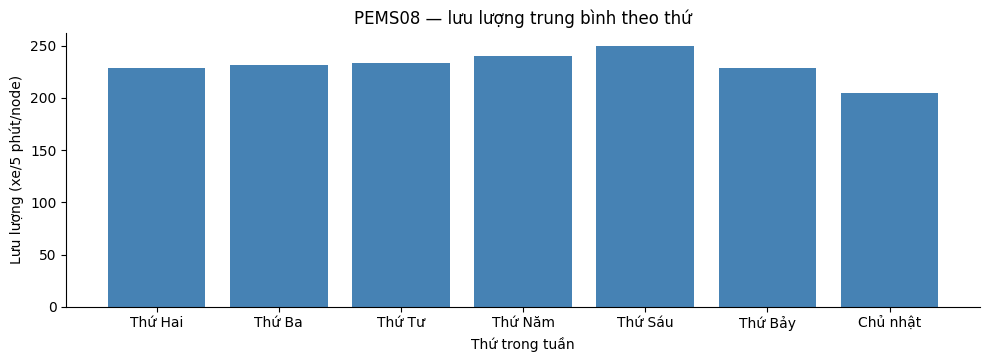

In [91]:
plt.figure(figsize=(10, 4))
plt.bar(flow_by_weekday.index, flow_by_weekday.values, color='steelblue')
plt.title('PEMS08 — lưu lượng trung bình theo thứ')
plt.xlabel('Thứ trong tuần')
plt.ylabel('Lưu lượng (xe/5 phút/node)')
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(OUTPUT / '06_mean_flow_by_weekday.png', dpi=180)
plt.show()
plt.close()


## 22. Đọc index train

Mỗi tuple là `(bắt đầu input, bắt đầu nhãn, kết thúc nhãn)`; điểm kết thúc không được lấy.
Số mẫu dưới đây là số cửa sổ forecast. Giữ toàn bộ index đúng như run thực tế [S6].


In [92]:
with open(DATA / 'train_index.pkl', 'rb') as file:
    train_index = np.array(pickle.load(file, encoding='latin1'))
print('Số mẫu train:', len(train_index))
print('Cửa sổ đầu/cuối:', train_index[0], train_index[-1])


Số mẫu train: 10700
Cửa sổ đầu/cuối: [ 0 12 24] [10699 10711 10723]


## 23. Đọc index validation


In [93]:
with open(DATA / 'valid_index.pkl', 'rb') as file:
    valid_index = np.array(pickle.load(file, encoding='latin1'))
print('Số mẫu validation:', len(valid_index))
print('Cửa sổ đầu/cuối:', valid_index[0], valid_index[-1])


Số mẫu validation: 3567
Cửa sổ đầu/cuối: [10700 10712 10724] [14266 14278 14290]


## 24. Đọc index test


In [94]:
with open(DATA / 'test_index.pkl', 'rb') as file:
    test_index = np.array(pickle.load(file, encoding='latin1'))
print('Số mẫu test:', len(test_index))
print('Cửa sổ đầu/cuối:', test_index[0], test_index[-1])


Số mẫu test: 3566
Cửa sổ đầu/cuối: [14267 14279 14291] [17832 17844 17856]


## 25. Bảng số mẫu từ index thực tế


In [95]:
split_counts = pd.DataFrame({
    'Tập': ['Train', 'Validation', 'Test'],
    'Số cửa sổ': [len(train_index), len(valid_index), len(test_index)]
})
split_counts['Tỷ lệ (%)'] = split_counts['Số cửa sổ'] / split_counts['Số cửa sổ'].sum() * 100
display(split_counts)
split_counts.to_csv(OUTPUT / 'pems08_split_counts.csv', index=False, encoding='utf-8-sig')


,Tập,Số cửa sổ,Tỷ lệ (%)
0,Train,10700,60.001122
1,Validation,3567,20.002243
2,Test,3566,19.996635


## 26. Kiểm tra độ dài và biên cửa sổ
Input 12 bước và nhãn 12 bước; toàn bộ cửa sổ stride 1 phủ đúng dữ liệu.


In [96]:
all_index = np.concatenate([train_index, valid_index, test_index])
assert np.all(all_index[:, 1] - all_index[:, 0] == 12)
assert np.all(all_index[:, 2] - all_index[:, 1] == 12)
assert np.all(all_index[:, 0] >= 0)
assert np.all(all_index[:, 2] <= len(data))
assert np.array_equal(all_index[:, 0], np.arange(len(data) - 23))
print('Kiểm tra đạt. Tổng cửa sổ:', len(all_index))


Kiểm tra đạt. Tổng cửa sổ: 17833


## 27. Kiểm tra chồng nhãn ở ranh giới

Vì index mỗi tập liên tục, miền nhãn là từ thời điểm bắt đầu nhãn đầu tiên đến
thời điểm kết thúc nhãn cuối cùng (không lấy điểm cuối).
Giữ nguyên protocol repo, không tự sửa split.


In [97]:
train_targets = np.arange(train_index[0, 1], train_index[-1, 2])
valid_targets = np.arange(valid_index[0, 1], valid_index[-1, 2])
test_targets = np.arange(test_index[0, 1], test_index[-1, 2])

overlap = pd.DataFrame({
    'Ranh giới': ['Train / Validation', 'Validation / Test', 'Train / Test'],
    'Số bước nhãn trùng': [len(np.intersect1d(train_targets, valid_targets)),
                          len(np.intersect1d(valid_targets, test_targets)),
                          len(np.intersect1d(train_targets, test_targets))]
})
display(overlap)
overlap.to_csv(OUTPUT / 'pems08_overlap_summary.csv', index=False, encoding='utf-8-sig')


,Ranh giới,Số bước nhãn trùng
0,Train / Validation,11
1,Validation / Test,11
2,Train / Test,0


- PEMS08: 17.856 thời điểm, 170 node, chu kỳ 5 phút, 62 ngày.
- Ba đại lượng gốc không có NaN. Flow và Occupancy mỗi loại có 10.560 số 0; Speed không có số 0.
- Index forecast: 10.700 train, 3.567 validation, 3.566 test; hai ranh giới liền kề chồng 11 bước nhãn.
- Thống kê/biểu đồ giữ nguyên số 0, không sửa dữ liệu hay chia tập.
- Các hình tự vẽ có chú thích nguồn ngay dưới hình và link nguồn ở mục 28.
- Hình/bảng cũ có thể vẫn còn trong thư mục output; sáu hình của bản này được ghi tên ngay trong ô code tương ứng.


# Hình và minh chứng dùng cho chương 3–5

Các ô sau chỉ đọc kết quả forecast đã chạy, không huấn luyện lại. Nguồn: run
`PEMS08-repo96-author-pretrained`, attempt `0001`, checkpoint tốt nhất epoch 68.
File đầu vào đã được copy từ backup xác minh về `artifacts/report-inputs/PEMS08/`.
Thư mục này bị Git bỏ qua; nếu chuyển máy, cần mang theo nó để chạy lại phần minh chứng.
Output hiện tại được lưu trong notebook nên có thể xem ngay khi chưa copy các file lớn.


## 30. Kiến trúc LSTTN

Sơ đồ tự vẽ theo mã nguồn LSTTN [S6]. Không phải bằng chứng huấn luyện mới.
Các hình dùng trong LaTeX sẽ được gom vào một file ZIP ở cuối notebook.


In [98]:
import json
import hashlib
import zipfile

REPORT = ROOT / 'results' / 'report_figures'
REPORT.mkdir(parents=True, exist_ok=True)
INPUT = ROOT / 'artifacts' / 'report-inputs' / 'PEMS08'
figure_files = []


In [99]:
boxes = {
    'long': (0.13, 0.82, 'Lịch sử dài\n4.032 bước'),
    'encoder': (0.43, 0.82, 'Transformer\nCheckpoint đóng băng'),
    'lt': (0.77, 0.91, 'Xu hướng dài hạn'),
    'period': (0.77, 0.64, 'Chu kỳ ngày / tuần'),
    'short': (0.13, 0.31, 'Lịch sử ngắn\n12 bước'),
    'gwn': (0.43, 0.31, 'Graph WaveNet'),
    'fusion': (0.77, 0.31, 'Hợp nhất đặc trưng'),
    'output': (0.77, 0.07, 'Dự báo 12 bước')
}
edges = [('long', 'encoder'), ('encoder', 'lt'), ('encoder', 'period'),
         ('lt', 'fusion'), ('period', 'fusion'), ('short', 'gwn'),
         ('gwn', 'fusion'), ('fusion', 'output')]


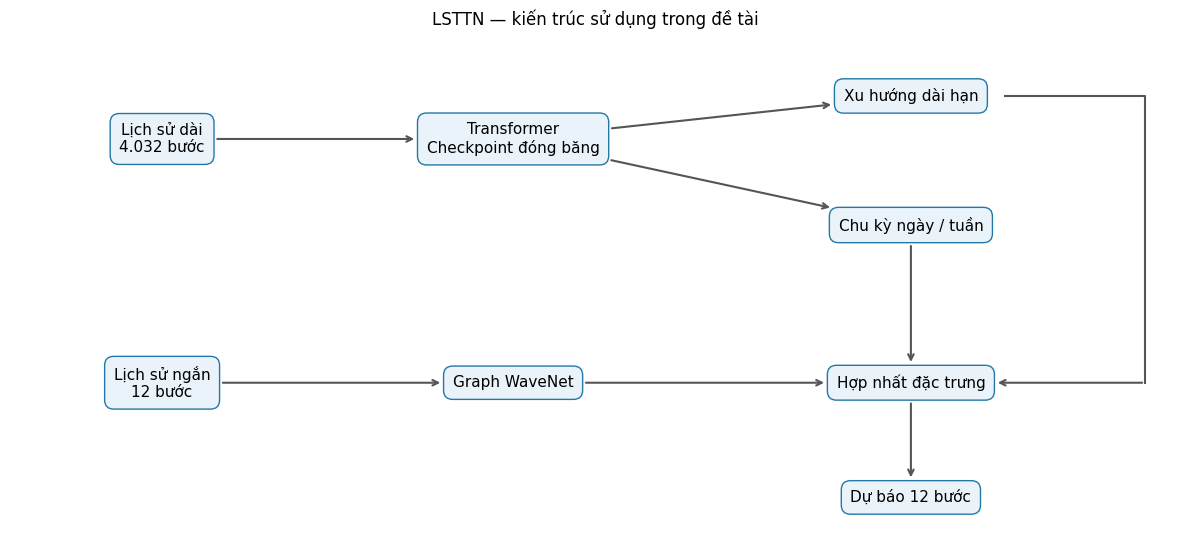

In [100]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set(xlim=(0, 1), ylim=(-0.04, 1.04), title='LSTTN — kiến trúc sử dụng trong đề tài')
ax.axis('off')
artists = {}
for key, (x, y, label) in boxes.items():
    artists[key] = ax.text(x, y, label, ha='center', va='center', fontsize=11,
                          bbox={'boxstyle': 'round,pad=.6', 'fc': '#eaf3fa', 'ec': '#2378a8'})
for left, right in edges:
    if left == 'lt' and right == 'fusion':
        continue  # Vẽ đường riêng bên phải để không đi xuyên hộp chu kỳ.
    ax.annotate('', xy=boxes[right][:2], xytext=boxes[left][:2],
                arrowprops={'arrowstyle': '->', 'color': '#555555', 'lw': 1.5,
                            'patchA': artists[left].get_bbox_patch(), 'patchB': artists[right].get_bbox_patch()})
ax.plot([.85, .97, .97], [.91, .91, .31], color='#555555', lw=1.5)
ax.annotate('', xy=boxes['fusion'][:2], xytext=(.97, .31),
            arrowprops={'arrowstyle': '->', 'color': '#555555', 'lw': 1.5, 'patchB': artists['fusion'].get_bbox_patch()})
fig.tight_layout(rect=[0, .05, 1, 1])
fig.savefig(REPORT / 'lsttn_architecture.png', dpi=180)
figure_files.append(REPORT / 'lsttn_architecture.png')
plt.show()
plt.close()


## 31. Kiểm hash và trạng thái run đã hoàn thành


In [101]:
run_result = json.loads((INPUT / 'result.json').read_text(encoding='utf-8'))
export_hashes = json.loads((INPUT / 'export_hashes.json').read_text(encoding='utf-8'))
for item in export_hashes:
    actual_hash = hashlib.sha256((INPUT / item['file']).read_bytes()).hexdigest()
    assert actual_hash == item['sha256'], item['file']
assert run_result['status'] == 'success' and run_result['exit_code'] == 0
print('Run:', run_result['id'], '| attempt:', run_result['attempt'])
print('Trạng thái:', run_result['status'], '| exit code:', run_result['exit_code'])
print('Thời gian run (giờ):', round(run_result['elapsed_seconds'] / 3600, 3))
print('Đã kiểm SHA-256:', len(export_hashes), 'file export / metadata')


Run: PEMS08-repo96-author-pretrained | attempt: 1
Trạng thái: success | exit code: 0
Thời gian run (giờ): 16.585
Đã kiểm SHA-256: 113 file export / metadata


## 32. Đọc prediction, target và index đã export
Trục mảng: mẫu, horizon, node. Chỉ đọc CPU; không chạy model.


In [102]:
prediction_batches, target_batches, index_batches = [], [], []
for file in sorted(INPUT.glob('batch_*.npz')):
    with np.load(file, allow_pickle=False) as batch:
        prediction_batches.append(batch['prediction'])
        target_batches.append(batch['target'])
        index_batches.append(batch['index'])
predictions = np.concatenate(prediction_batches).astype('float64')
targets = np.concatenate(target_batches).astype('float64')
export_index = np.concatenate(index_batches)
print('Prediction:', predictions.shape, '| Target:', targets.shape)


Prediction: (3566, 12, 170) | Target: (3566, 12, 170)


In [103]:
assert predictions.shape == targets.shape == (3566, 12, 170)
assert np.array_equal(export_index, test_index)
assert np.isfinite(predictions).all() and np.isfinite(targets).all()
target_positions = export_index[:, 1, None] + np.arange(12)[None, :]
assert np.allclose(targets, flow[target_positions], atol=0.001, rtol=0)
print('PASS: đủ 3.566 mẫu test; index đúng; target khớp Flow gốc.')


PASS: đủ 3.566 mẫu test; index đúng; target khớp Flow gốc.


## 33. Tính lại metric toàn bộ test PEMS08

MAE giữ nhãn 0; RMSE loại nhãn 0; MAPE loại nhãn nhỏ hơn 0,01 và hiển thị %.
Các mask này theo protocol repo, không áp chung một mask cho cả ba metric.


In [104]:
metric_rows = []
for h in [3, 6, 12]:
    p = predictions[:, h - 1, :]
    y = targets[:, h - 1, :]
    valid_rmse = y != 0
    valid_mape = y >= 0.01
    metric_rows.append({'minutes': h * 5, 'MAE': np.abs(p - y).mean(),
                        'RMSE': np.sqrt(np.square(p[valid_rmse] - y[valid_rmse]).mean()),
                        'MAPE_percent': (np.abs(p[valid_mape] - y[valid_mape]) / y[valid_mape]).mean() * 100})
recalculated = pd.DataFrame(metric_rows)
display(recalculated)


,minutes,MAE,RMSE,MAPE_percent
0,15,13.399619,21.644651,8.991706
1,30,14.193403,23.488661,9.927707
2,60,15.388007,25.568519,11.378056


In [105]:
recorded_metrics = pd.read_csv(ROOT / 'results' / 'experiment_metrics.csv')
recorded_pems08 = recorded_metrics[recorded_metrics['dataset'] == 'PEMS08'].sort_values('minutes')
assert np.allclose(recalculated[['MAE', 'RMSE', 'MAPE_percent']],
                   recorded_pems08[['MAE', 'RMSE', 'MAPE_percent']], atol=1e-8, rtol=0)
recalculated.to_csv(REPORT / 'recomputed_metrics.csv', index=False)
print('PASS: metric tính lại khớp số liệu báo cáo ở cả ba horizon.')


PASS: metric tính lại khớp số liệu báo cáo ở cả ba horizon.


## 34. Dự báo và thực tế tại một node

Chọn trước node 0 và ba ngày đầu test, không chọn đoạn theo chất lượng dự báo.
Mỗi đầu ra đặt đúng timestamp mục tiêu bằng `forecast_start + horizon - 1`.
Hình minh họa một node; metric ở mục 33 là toàn bộ test, không phải metric riêng node 0.
Nguồn hình: export thực tế của run PEMS08; chưa có baseline Persistence/HA tự chạy.


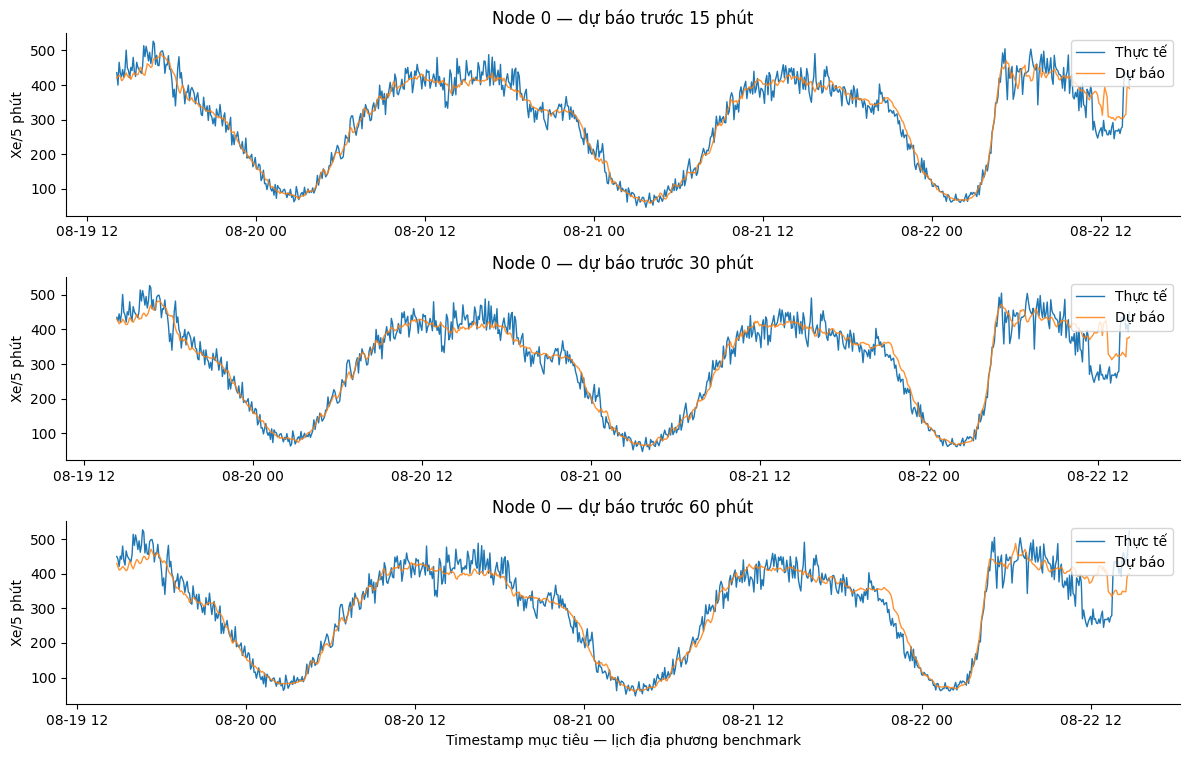

In [106]:
NODE = 0
NUMBER_OF_WINDOWS = 3 * 288
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharey=True)
for ax, h in zip(axes, [3, 6, 12]):
    target_time = time[export_index[:NUMBER_OF_WINDOWS, 1] + h - 1]
    ax.plot(target_time, targets[:NUMBER_OF_WINDOWS, h - 1, NODE], label='Thực tế', lw=1)
    ax.plot(target_time, predictions[:NUMBER_OF_WINDOWS, h - 1, NODE], label='Dự báo', lw=1, alpha=.85)
    ax.set(title=f'Node {NODE} — dự báo trước {h * 5} phút', ylabel='Xe/5 phút')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Timestamp mục tiêu — lịch địa phương benchmark')
fig.tight_layout(rect=[0, .04, 1, 1])
fig.savefig(REPORT / 'pems08_forecast.png', dpi=180)
figure_files.append(REPORT / 'pems08_forecast.png')
plt.show()
plt.close()


## 35. Sai số PEMS08 theo khoảng dự báo
Nguồn: metric tính lại từ export đầy đủ, đã đối chiếu bảng báo cáo.


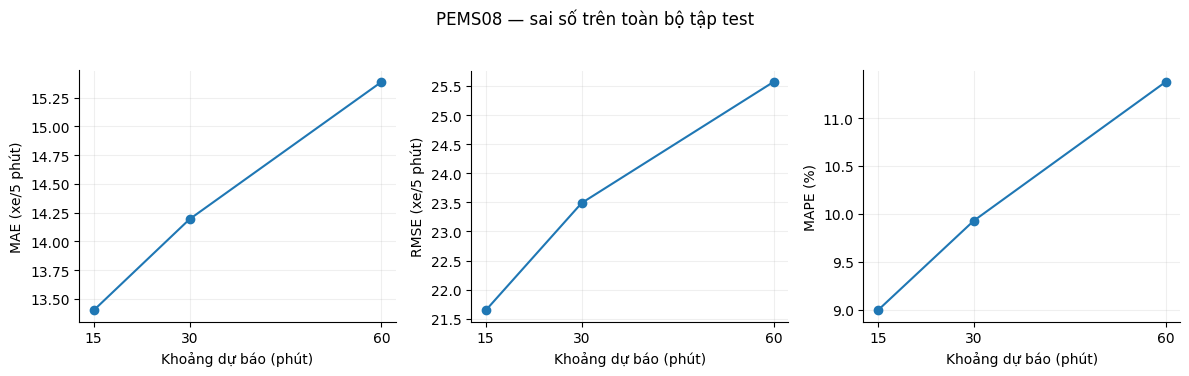

In [107]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric, label in zip(axes, ['MAE', 'RMSE', 'MAPE_percent'], ['MAE (xe/5 phút)', 'RMSE (xe/5 phút)', 'MAPE (%)']):
    ax.plot(recalculated['minutes'], recalculated[metric], marker='o')
    ax.set(xticks=[15, 30, 60], xlabel='Khoảng dự báo (phút)', ylabel=label)
    ax.grid(alpha=.2)
fig.suptitle('PEMS08 — sai số trên toàn bộ tập test')
fig.tight_layout(rect=[0, .05, 1, .95])
fig.savefig(REPORT / 'pems08_horizon_metrics.png', dpi=180)
figure_files.append(REPORT / 'pems08_horizon_metrics.png')
plt.show()
plt.close()


## 36. Gom hình để tải và chèn vào LaTeX

ZIP chứa sáu hình EDA, ba hình báo cáo, bảng metric tính lại, nguồn hình và minh chứng thực thi.
Giải nén cạnh file LaTeX để có thư mục `report_figures/`. Không chứa checkpoint hoặc dữ liệu lớn.


In [108]:
eda_names = ['01_histogram_flow.png', '02_histogram_occupancy.png', '03_histogram_speed.png',
             '04_node_timeseries.png', '05_mean_flow_by_hour.png', '06_mean_flow_by_weekday.png']
figure_files += [OUTPUT / name for name in eda_names]
evidence = {'run_id': run_result['id'], 'attempt': run_result['attempt'], 'run_status': run_result['status'],
            'export_files_sha_verified': len(export_hashes), 'test_samples': len(predictions),
            'metrics_recomputed_match': True, 'prediction_alignment_verified': True,
            'note': 'CPU analysis of an existing completed run; not a new training run.'}
(REPORT / 'execution_evidence.json').write_text(json.dumps(evidence, indent=2), encoding='utf-8')
(REPORT / 'figure_sources.txt').write_text('EDA: PEMS08 [S3-S5], Flow matched LSTTN [S6].\nArchitecture: author LSTTN source [S6].\nForecast and metrics: run PEMS08-repo96-author-pretrained / 0001, best epoch 68.\n', encoding='utf-8')


167

In [109]:
archive = REPORT.parent / 'report_figures.zip'
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as bundle:
    for file in figure_files:
        bundle.write(file, 'report_figures/' + file.name)
    for name in ['recomputed_metrics.csv', 'execution_evidence.json', 'figure_sources.txt']:
        bundle.write(REPORT / name, 'report_figures/' + name)
print('Tải hình:', archive.relative_to(ROOT))
print('Hoàn tất: 9 hình; kiểm hash, index, target và metric đều đạt.')


Tải hình: results\report_figures.zip
Hoàn tất: 9 hình; kiểm hash, index, target và metric đều đạt.
